# 04 · Query-based detector: RT-DETR-l

* `rtdetr_base` – 300 queries, 100 denoising queries, 1344 px, batch 4.
* `rtdetr_q500` – 500 queries / 200 denoising queries (dense scenes have up to 180 objects).
* `rtdetr_cost` – Hungarian matcher cost changed to class 2 / L1 5 / GIoU 5 / no-object 0.1.
* `rtdetr_s5` – same config as `rtdetr_cost` with a different frame subsample (see note) – a measure of run-to-run noise.
* `*_1536` – input size 1536. `rtdetr_s4_*` – 2.5× more training frames (every 4th frame).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from hw2 import CLASSES
from hw2.analysis import load_run, metrics_table, curve, error_breakdown, worst_frames, draw
from hw2.data import find_data_root, fold_frames, load_all, make_folds, subsample

sns.set_theme(style="whitegrid", context="notebook")
IMG = Path("../images"); IMG.mkdir(exist_ok=True)
frames, boxes = load_all(find_data_root())
val = subsample(fold_frames(frames, make_folds(frames), 0), 4)   # the validation frames every run was scored on
vpath = val.set_index("key").path
vboxes = boxes[boxes.key.isin(set(val.key))]


In [2]:
def table(runs):
    return metrics_table(runs).round(4)

def per_class(runs):
    rows = {r: {c: json.load(open(f"../runs/{r}/metrics.json"))[f"AP_{c}"] for c in CLASSES} for r in runs}
    return pd.DataFrame(rows).T.round(3)

def plot_curves(runs, title, fname, x="epoch"):
    fig, ax = plt.subplots(figsize=(7, 4))
    for r in runs:
        c = curve(load_run(r))
        ax.plot(c[x], c.mAP, marker="o", ms=4, label=r)
    ax.set_xlabel(x if x == "epoch" else "training time, min"); ax.set_ylabel("mAP@[.5:.95] on fold 0"); ax.set_title(title); ax.legend()
    fig.tight_layout(); fig.savefig(IMG / fname, dpi=140); plt.show()

def breakdown(runs, thr=0.3):
    rows = {}
    for r in runs:
        p = load_run(r)["val_preds"]
        rows[r] = error_breakdown(p, vboxes, val.key, score_thr=thr)
    return pd.DataFrame(rows).T

def crop_window(gt, W, H, frac=0.45):
    """The (frac*W x frac*H) window that holds the most ground-truth centres."""
    g = gt[gt.ignore == 0]
    cx, cy = g.x + g.w / 2, g.y + g.h / 2
    w, h = int(W * frac), int(H * frac)
    best = max(((x0, y0) for x0 in np.linspace(0, W - w, 4).astype(int) for y0 in np.linspace(0, H - h, 4).astype(int)),
               key=lambda p: ((cx >= p[0]) & (cx < p[0] + w) & (cy >= p[1]) & (cy < p[1] + h)).sum())
    return best[0], best[1], best[0] + w, best[1] + h

def show_cases(runs, cases, fname, thr=0.3):
    """One row per failure case, one column per run: green = ground truth, grey = ignored region, red = detections."""
    fig, axes = plt.subplots(len(cases), len(runs), figsize=(6.5 * len(runs), 4.2 * len(cases)), squeeze=False)
    preds = {r: load_run(r)["val_preds"] for r in runs}
    for i, (key, why) in enumerate(cases):
        gt = vboxes[vboxes.key == key]
        fr = val.set_index("key").loc[key]
        crop = crop_window(gt, int(fr.width), int(fr.height))
        for j, r in enumerate(runs):
            axes[i, j].imshow(draw(vpath[key], preds[r][preds[r].key == key], gt, thr, crop))
            axes[i, j].set_title(f"{r}: {why}", fontsize=9); axes[i, j].axis("off")
    fig.tight_layout(); fig.savefig(IMG / fname, dpi=120); plt.show()

def pick_cases(run, n_sample=150):
    """Three failure types for one run: missed small objects, class confusions, false alarms."""
    p = load_run(run)["val_preds"]
    w = worst_frames(p, vboxes, val.key, n_sample=n_sample)
    miss = w.sort_values("missed_small", ascending=False).index[0]
    conf = w[w.index != miss].sort_values("cls", ascending=False).index[0]
    fp = w[~w.index.isin([miss, conf])].sort_values("background", ascending=False).index[0]
    return w, [(miss, "most missed small objects"), (conf, "most class confusions"), (fp, "most background false alarms")]


## Metrics

In [3]:
R = ['rtdetr_base', 'rtdetr_q500', 'rtdetr_cost', 'rtdetr_s5', 'rtdetr_s5_1536', 'rtdetr_s4_1344', 'rtdetr_s4_1536']
table(R)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_min
run,,,,,,,,,
rtdetr_base,0.2971,0.5424,0.2816,0.1085,0.2059,0.4859,0.4808,10.04,105.9
rtdetr_q500,0.2973,0.5414,0.2821,0.0970,0.2230,0.4742,0.5084,12.21,111.7
rtdetr_cost,0.3004,0.5436,0.2885,0.1059,0.2152,0.4667,0.4731,12.05,97.7
rtdetr_s5,0.2945,0.5291,0.2835,0.0973,0.2109,0.4656,0.4612,12.57,108.4
rtdetr_s5_1536,0.3096,0.5510,0.2993,0.1024,0.2329,0.4909,0.4729,10.24,147.1
rtdetr_s4_1344,0.2808,0.5073,0.2670,0.0804,0.2073,0.4410,0.4340,12.31,240.4
rtdetr_s4_1536,0.2911,0.5180,0.2826,0.0884,0.2081,0.4737,0.4396,9.98,311.1


In [4]:
per_class(R)

,person,bicycle,car,van,truck,tricycle,bus,motor
rtdetr_base,0.228,0.116,0.520,0.256,0.233,0.333,0.569,0.130
rtdetr_q500,0.223,0.119,0.524,0.236,0.237,0.333,0.593,0.123
rtdetr_cost,0.236,0.111,0.523,0.261,0.233,0.339,0.577,0.133
rtdetr_s5,0.233,0.093,0.520,0.249,0.244,0.309,0.597,0.120
rtdetr_s5_1536,0.238,0.110,0.528,0.252,0.303,0.320,0.602,0.130
rtdetr_s4_1344,0.221,0.064,0.512,0.216,0.223,0.294,0.625,0.101
rtdetr_s4_1536,0.221,0.072,0.521,0.236,0.240,0.281,0.650,0.115


## RT-DETR vs CNN detectors during training

The curves use each framework's own per-epoch validation on every 20th frame of fold 0 (torchvision runs every 2nd epoch with our evaluator, Ultralytics every epoch with its own mAP), so use them for trends, not for decimals.

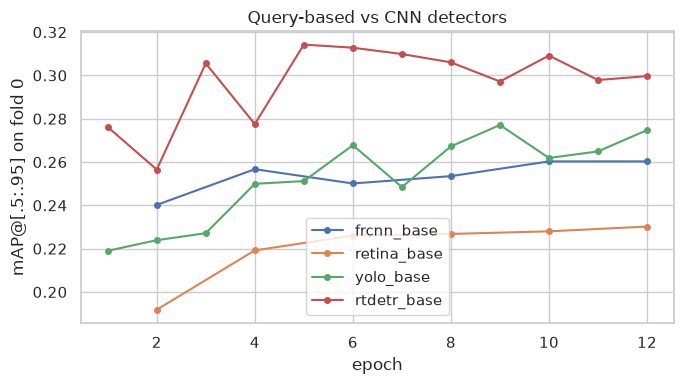

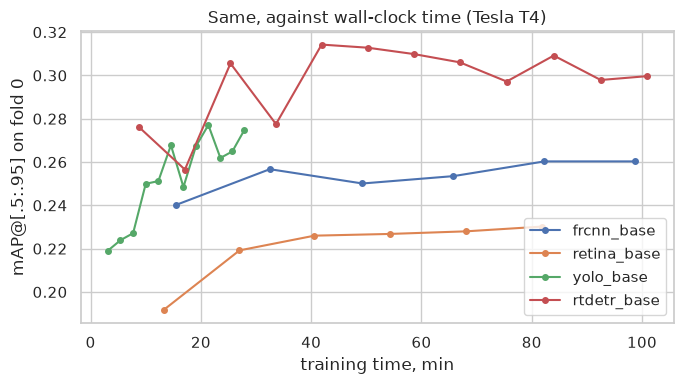

In [5]:
plot_curves(['frcnn_base', 'retina_base', 'yolo_base', 'rtdetr_base'], 'Query-based vs CNN detectors', 'curve_rtdetr_vs_cnn.png')
plot_curves(['frcnn_base', 'retina_base', 'yolo_base', 'rtdetr_base'], 'Same, against wall-clock time (Tesla T4)', 'curve_rtdetr_vs_cnn_time.png', x='minutes')

## More frames did not help

Training on 2.5× more (neighbouring, near-identical) frames lowered the held-out mAP: the model saturates after 1-2 epochs and then fits the training clips.

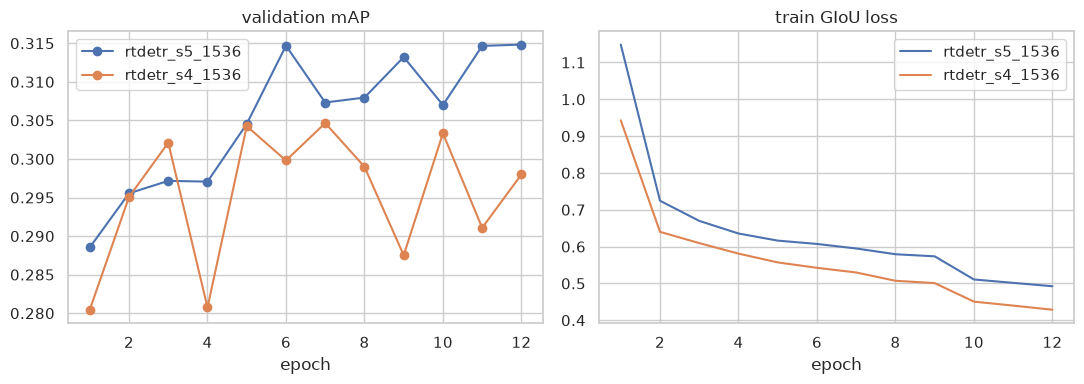

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for r in ['rtdetr_s5_1536', 'rtdetr_s4_1536']:
    c = curve(load_run(r)); ax[0].plot(c.epoch, c.mAP, marker='o', label=r)
ax[0].set_title('validation mAP'); ax[0].set_xlabel('epoch'); ax[0].legend()
for r in ['rtdetr_s5_1536', 'rtdetr_s4_1536']:
    h = load_run(r)['history']; ax[1].plot(h.epoch, h['train/giou_loss'], label=r)
ax[1].set_title('train GIoU loss'); ax[1].set_xlabel('epoch'); ax[1].legend(); fig.tight_layout(); fig.savefig(IMG / 'rtdetr_more_frames.png', dpi=140)

## Where the errors are

In [7]:
bd = breakdown(['rtdetr_base', 'rtdetr_q500', 'rtdetr_cost', 'rtdetr_s5_1536']); bd

,tp,duplicate,cls,loc,ignored,background,missed_small,missed_medium,missed_large,recall_small,recall_medium,recall_large
rtdetr_base,52235.0,2705.0,8955.0,7048.0,28855.0,19612.0,6071.0,9428.0,797.0,0.521,0.790,0.928
rtdetr_q500,51667.0,1748.0,8817.0,7207.0,32084.0,20300.0,6455.0,9640.0,769.0,0.491,0.785,0.930
rtdetr_cost,52414.0,4377.0,9240.0,8741.0,34002.0,22015.0,6011.0,9332.0,774.0,0.526,0.792,0.930
rtdetr_s5_1536,52427.0,2995.0,8841.0,8667.0,34314.0,22358.0,5996.0,9354.0,754.0,0.527,0.791,0.932


## Failure cases (3)

[('uav0000124_00944_v_0000165', 'most missed small objects'), ('uav0000288_00001_v_0000033', 'most class confusions'), ('uav0000117_02622_v_0000121', 'most background false alarms')]


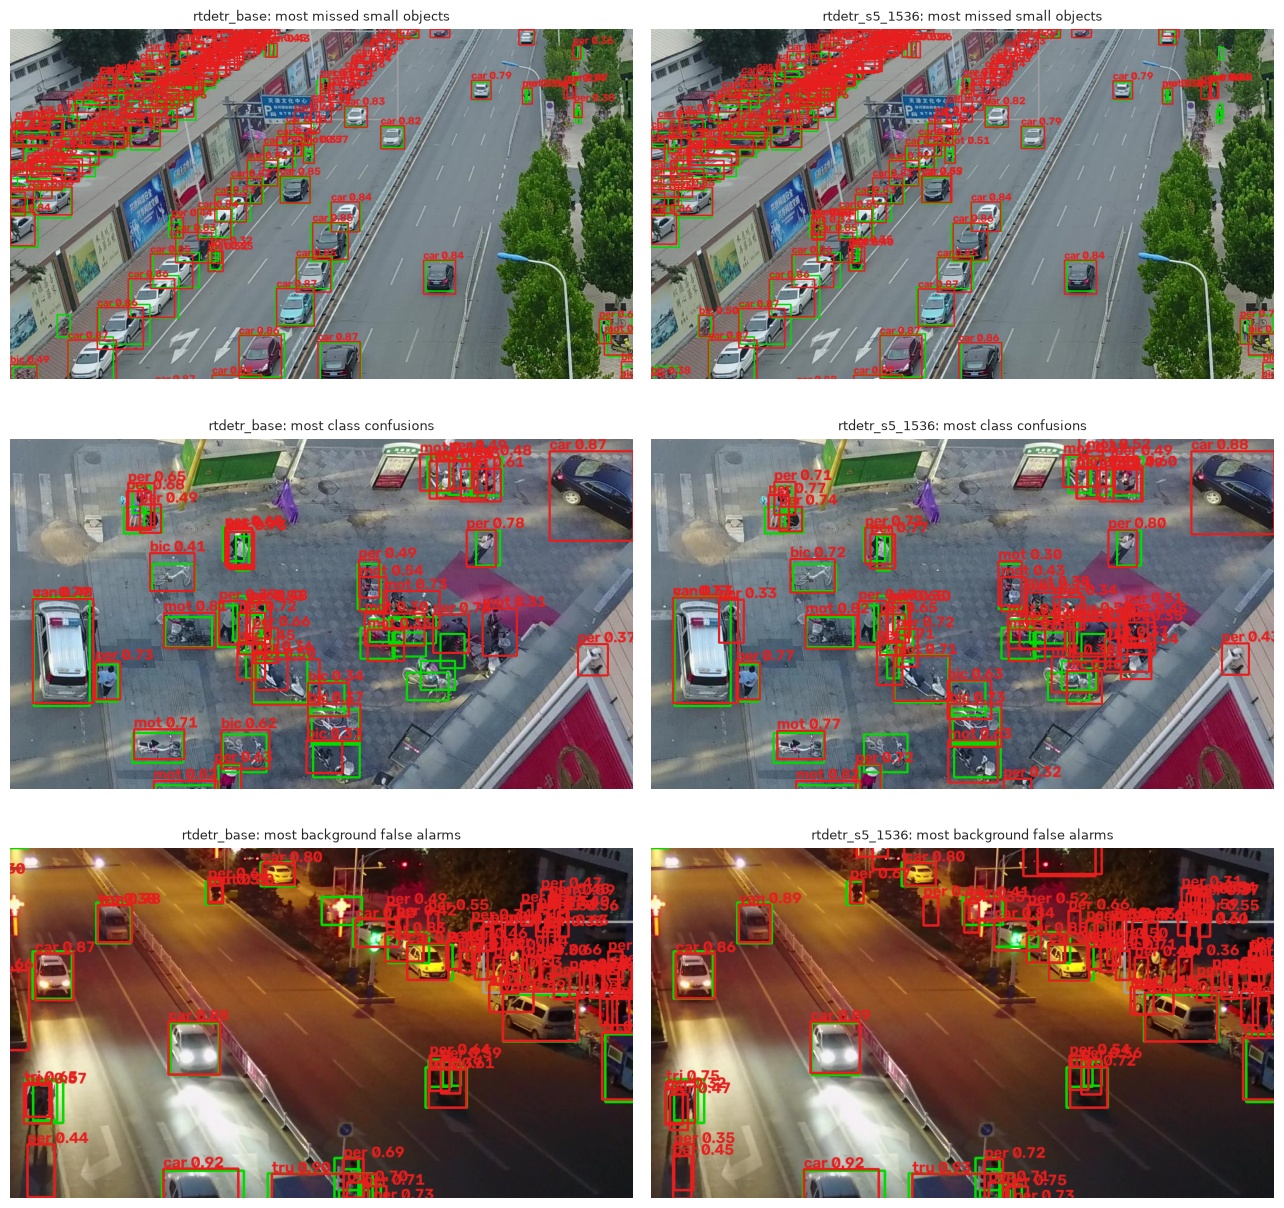

In [8]:
w, cases = pick_cases('rtdetr_s5_1536')
print(cases)
show_cases(['rtdetr_base', 'rtdetr_s5_1536'], cases, 'fail_rtdetr.png')